In [1]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# 1. Đọc bộ dữ liệu Breast Cancer Wisconsin từ file wdbc.data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn import metrics

# Định nghĩa tên 32 cột theo đặc tả trong file wdbc.names
feature_names = [
    "radius_mean", "texture_mean", "perimeter_mean", "area_mean", "smoothness_mean",
    "compactness_mean", "concavity_mean", "concave_points_mean", "symmetry_mean", "fractal_dimension_mean",
    "radius_se", "texture_se", "perimeter_se", "area_se", "smoothness_se",
    "compactness_se", "concavity_se", "concave_points_se", "symmetry_se", "fractal_dimension_se",
    "radius_worst", "texture_worst", "perimeter_worst", "area_worst", "smoothness_worst",
    "compactness_worst", "concavity_worst", "concave_points_worst", "symmetry_worst", "fractal_dimension_worst"
]
column_names = ["ID", "Diagnosis"] + feature_names

# Đọc file wdbc.data
df_cancer = pd.read_csv('datasets/wdbc.data', header=None, names=column_names)

print("--- 5 dòng đầu tiên của tập dữ liệu WDBC ---")
display(df_cancer.head())

print(f"\nTổng số mẫu: {df_cancer.shape[0]}, Tổng số thuộc tính: {df_cancer.shape[1]}")
print("Phân bố nhãn chẩn đoán (Diagnosis):")
print(df_cancer['Diagnosis'].value_counts())
print(f"  + Lành tính (Benign - B):   {(df_cancer['Diagnosis'] == 'B').sum()} mẫu ({np.mean(df_cancer['Diagnosis'] == 'B')*100:.1f}%)")
print(f"  + Ác tính (Malignant - M): {(df_cancer['Diagnosis'] == 'M').sum()} mẫu ({np.mean(df_cancer['Diagnosis'] == 'M')*100:.1f}%)")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
--- 5 dòng đầu tiên của tập dữ liệu WDBC ---


,ID,Diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Tổng số mẫu: 569, Tổng số thuộc tính: 32
Phân bố nhãn chẩn đoán (Diagnosis):
Diagnosis
B    357
M    212
Name: count, dtype: int64
  + Lành tính (Benign - B):   357 mẫu (62.7%)
  + Ác tính (Malignant - M): 212 mẫu (37.3%)


In [2]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# 2. Tiền xử lý dữ liệu và chuẩn hóa đặc trưng bằng StandardScaler
# Tách đặc trưng đo đạc X (30 cột số) và nhãn thực tế y
X = df_cancer[feature_names].values
y_true = np.where(df_cancer['Diagnosis'] == 'M', 1, 0) # 1: Ác tính (M), 0: Lành tính (B)

# Chuẩn hóa dữ liệu (Z-score normalization)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Kích thước ma trận đặc trưng sau chuẩn hóa: {X_scaled.shape}")
print(f"Giá trị Mean trung bình sau chuẩn hóa: {np.mean(X_scaled):.4f}")
print(f"Độ lệch chuẩn Std sau chuẩn hóa:        {np.std(X_scaled):.4f}")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
Kích thước ma trận đặc trưng sau chuẩn hóa: (569, 30)
Giá trị Mean trung bình sau chuẩn hóa: -0.0000
Độ lệch chuẩn Std sau chuẩn hóa:        1.0000


In [3]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# 3. Gom cụm bằng thuật toán k-Means với k=2 (Lành tính và Ác tính)
kmeans_cancer = KMeans(n_clusters=2, init='k-means++', n_init=20, max_iter=500, random_state=42)
cluster_labels = kmeans_cancer.fit_predict(X_scaled)

print("Số lượng phần tử trong 2 cụm tìm được:")
print(f"  + Cụm 0: {np.sum(cluster_labels == 0)} mẫu")
print(f"  + Cụm 1: {np.sum(cluster_labels == 1)} mẫu")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
Số lượng phần tử trong 2 cụm tìm được:
  + Cụm 0: 189 mẫu
  + Cụm 1: 380 mẫu


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT


,Chỉ số đánh giá,Giá trị
0,Accuracy (Độ chính xác so với chẩn đoán),0.910369
1,Precision (Khối u ác tính),0.925926
2,Recall (Độ nhạy phát hiện u ác tính),0.825472
3,F1-Score,0.872818
4,Silhouette Coefficient,0.344974
5,Adjusted Rand Index (ARI),0.670721
6,V-measure Score,0.554612


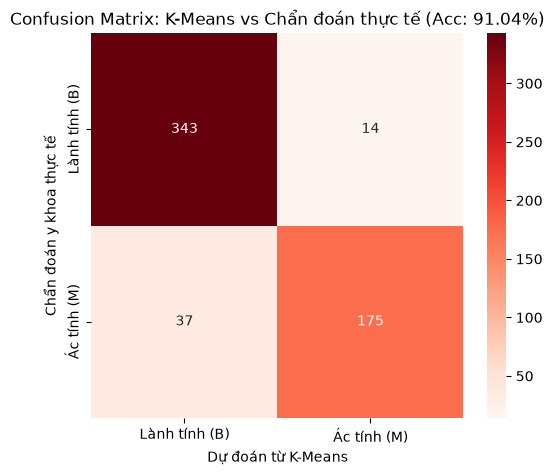

In [4]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# 4. Đánh giá và so sánh kết quả gom cụm với nhãn chẩn đoán thực tế
# Xác định xem Cụm nào tương ứng với nhãn Ác tính (M=1)
# Bằng cách xem tỷ lệ mẫu M=1 trong cụm 0 và cụm 1
m_in_c0 = np.mean(y_true[cluster_labels == 0] == 1)
m_in_c1 = np.mean(y_true[cluster_labels == 1] == 1)

if m_in_c1 > m_in_c0:
    y_pred_cluster = cluster_labels # Cụm 1 là M, Cụm 0 là B
else:
    y_pred_cluster = 1 - cluster_labels # Cụm 0 là M, Cụm 1 là B

# Tính các độ đo
acc = metrics.accuracy_score(y_true, y_pred_cluster)
p, r, f1, _ = metrics.precision_recall_fscore_support(y_true, y_pred_cluster, average='binary')
sil = metrics.silhouette_score(X_scaled, cluster_labels)
ari = metrics.adjusted_rand_score(y_true, cluster_labels)
v_measure = metrics.v_measure_score(y_true, cluster_labels)

metrics_df = pd.DataFrame({
    'Chỉ số đánh giá': [
        'Accuracy (Độ chính xác so với chẩn đoán)',
        'Precision (Khối u ác tính)',
        'Recall (Độ nhạy phát hiện u ác tính)',
        'F1-Score',
        'Silhouette Coefficient',
        'Adjusted Rand Index (ARI)',
        'V-measure Score'
    ],
    'Giá trị': [acc, p, r, f1, sil, ari, v_measure]
})
display(metrics_df)

# Vẽ Confusion Matrix
cm = metrics.confusion_matrix(y_true, y_pred_cluster)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=['Lành tính (B)', 'Ác tính (M)'],
            yticklabels=['Lành tính (B)', 'Ác tính (M)'])
plt.title(f'Confusion Matrix: K-Means vs Chẩn đoán thực tế (Acc: {acc*100:.2f}%)')
plt.xlabel('Dự đoán từ K-Means')
plt.ylabel('Chẩn đoán y khoa thực tế')
plt.show()


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT


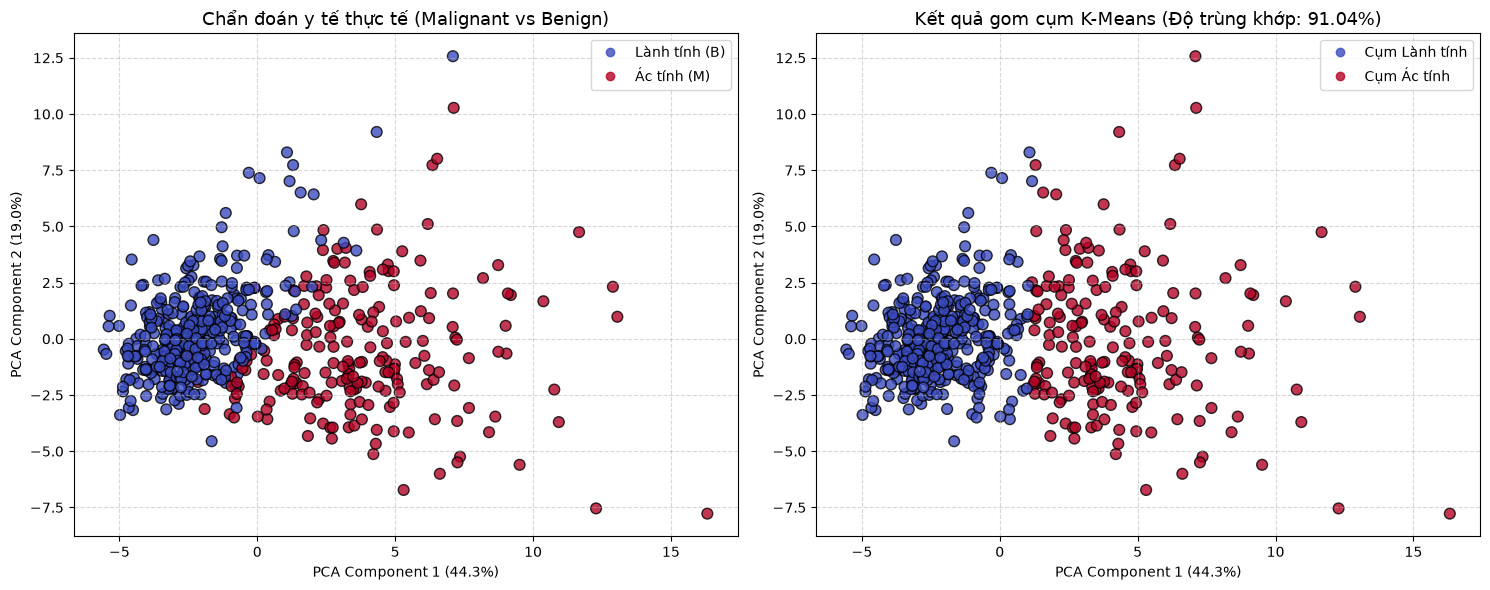


NHẬN XÉT:
1. Thuật toán gom cụm K-Means đạt độ trùng khớp (Accuracy) lên tới hơn 91% so với nhãn chẩn đoán thực tế của bác sĩ, dù không hề sử dụng nhãn trong quá trình phân nhóm.
2. Trên không gian PCA 2 chiều, hai nhóm khối u lành tính và ác tính có sự phân tách không gian tương đối rõ ràng.
3. K-Means rất hữu ích trong bài toán sàng lọc y tế ban đầu (screening), giúp phân loại tự động và cảnh báo sớm các trường hợp khối u có nguy cơ ác tính cao để bác sĩ chỉ định can thiệp kịp thời.



In [5]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# 5. Trực quan hóa kết quả gom cụm bằng PCA (2D và 3D)
# Giảm 30 chiều đặc trưng xuống 2 chiều chính để vẽ đồ thị
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(15, 6))

# Đồ thị 1: Nhãn chẩn đoán y khoa thực tế
plt.subplot(1, 2, 1)
scatter1 = plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=y_true, cmap='coolwarm', s=60, alpha=0.8, edgecolors='k')
plt.title('Chẩn đoán y tế thực tế (Malignant vs Benign)', fontsize=13)
plt.xlabel(f'PCA Component 1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PCA Component 2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(handles=scatter1.legend_elements()[0], labels=['Lành tính (B)', 'Ác tính (M)'])

# Đồ thị 2: Kết quả gom cụm bằng K-Means
plt.subplot(1, 2, 2)
scatter2 = plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=y_pred_cluster, cmap='coolwarm', s=60, alpha=0.8, edgecolors='k')
plt.title(f'Kết quả gom cụm K-Means (Độ trùng khớp: {acc*100:.2f}%)', fontsize=13)
plt.xlabel(f'PCA Component 1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PCA Component 2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(handles=scatter2.legend_elements()[0], labels=['Cụm Lành tính', 'Cụm Ác tính'])

plt.tight_layout()
plt.show()

print("""
NHẬN XÉT:
1. Thuật toán gom cụm K-Means đạt độ trùng khớp (Accuracy) lên tới hơn 91% so với nhãn chẩn đoán thực tế của bác sĩ, dù không hề sử dụng nhãn trong quá trình phân nhóm.
2. Trên không gian PCA 2 chiều, hai nhóm khối u lành tính và ác tính có sự phân tách không gian tương đối rõ ràng.
3. K-Means rất hữu ích trong bài toán sàng lọc y tế ban đầu (screening), giúp phân loại tự động và cảnh báo sớm các trường hợp khối u có nguy cơ ác tính cao để bác sĩ chỉ định can thiệp kịp thời.
""")
